In [1]:
import hoomd
import gsd.hoomd
# import matplotlib.pyplot as plt
import numpy as np
from hoomd.sqd_plugin import sqd_potential
# from hoomd.md import 

In [2]:
# from hoomd.azplugins import pair

In [3]:
nlist = hoomd.md.nlist.Cell(buffer=0.4, exclusions=('bond',))

In [4]:
# nlist

In [5]:
# ph = pair.Hertz(nlist)

In [6]:
sqd = sqd_potential.SquareDensity(nlist, default_r_cut=3.0)

In [7]:
sqd.params[('A', 'B')] = dict(A=1.0, B=2.0)
sqd.params[('B', 'B')] = dict(A=2.0, B=2.0)
sqd.params[('A', 'A')] = dict(A=2.0, B=2.0)


In [8]:
type(nlist)

hoomd.md.nlist.Cell

In [9]:
snapshot = gsd.hoomd.Frame()

# Place a polymer in the box.
N = 50
snapshot.particles.N = N
snapshot.particles.position = np.random.randint(-10,10,size=(N,3))
snapshot.particles.types = ['A','B']
snapshot.particles.typeid = ([0] * (N//2)) + ([1] * (N//2))
snapshot.configuration.box = [20, 20, 20, 0, 0, 0]

# Connect particles with bonds.
snapshot.bonds.N = N-1
snapshot.bonds.types = ['A-A']
snapshot.bonds.typeid = [0] * (N-1)
snapshot.bonds.group = np.dstack((np.arange(0,N-1),np.arange(1,N)))

with gsd.hoomd.open(name='molecular.gsd', mode='w') as f:
    f.append(snapshot)

In [10]:
fig,ax = plt.subplots(1,2)
ax[0].plot(snapshot.particles.position[:,0],snapshot.particles.position[:,1], marker="o")
ax[1].plot(snapshot.particles.position[:,0],snapshot.particles.position[:,2], marker="o")

NameError: name 'plt' is not defined

In [11]:
# Apply the harmonic potential on the bonds.
harmonic = hoomd.md.bond.Harmonic()
harmonic.params['A-A'] = dict(k=100, r0=1.0)

# Perform the MD simulation.
sim = hoomd.Simulation(device=hoomd.device.CPU(), seed=1)
sim.create_state_from_gsd(filename='molecular.gsd')
langevin = hoomd.md.methods.Langevin(filter=hoomd.filter.All(), kT=1.0)

integrator = hoomd.md.Integrator(dt=0.005,
                                 methods=[langevin],
                                 forces=[harmonic,sqd])
gsd_writer = hoomd.write.GSD(filename='molecular_trajectory.gsd',
                             trigger=hoomd.trigger.Periodic(10),
                             mode='wb')
sim.operations.integrator = integrator
sim.operations.writers.append(gsd_writer)

In [13]:
sim.run(10)
gsd_writer.flush()

before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!
before getting into the loop, fuck yeah!!


In [38]:
traj = gsd.hoomd.open("molecular_trajectory.gsd", 'r')

In [39]:
len(traj)

100

In [40]:
# new_snap = traj[0]

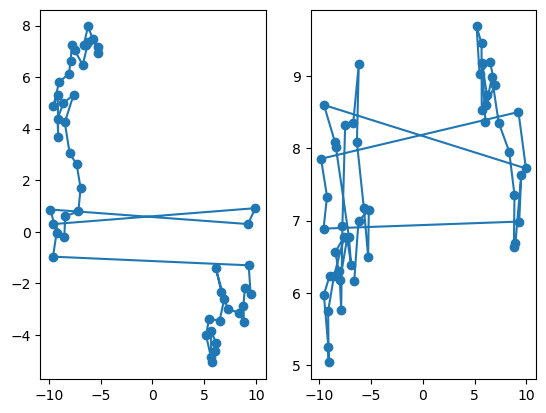

In [41]:
new_snap = traj[99]
fig,ax = plt.subplots(1,2)
ax[0].plot(new_snap.particles.position[:,0],new_snap.particles.position[:,1], marker="o")
ax[1].plot(new_snap.particles.position[:,0],new_snap.particles.position[:,2], marker="o")